# Exercise classifier: training and results

Phase 2A deliverable. This notebook trains and evaluates the two exercise classifiers
(Random Forest baseline and LSTM) on the 30-frame pose sequences, and shows the results.

It reuses the functions from `src/` (the same code the scripts run), so the numbers match
`train_classifier.py` and `train_lstm.py`. Data preparation is described in
[docs/ML_MODEL_DOCS.md](../docs/ML_MODEL_DOCS.md); run `src/make_sequences.py` first to
create `data/sequences.npz`.

In [1]:
import sys

sys.path.insert(0, "../src")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report

from train_classifier import load_sequences, make_model, split_by_video, summary_features
from train_lstm import predict, train_model

## 1. Data

Each sequence is 30 frames × 66 values (normalized x, y of the 33 MediaPipe landmarks).

In [2]:
X, y, videos, classes = load_sequences("../data/sequences.npz")
print("X shape:", X.shape, "(sequences, frames, features)")
pd.DataFrame({
    "videos": [len(set(videos[y == i])) for i in range(len(classes))],
    "sequences": np.bincount(y),
}, index=classes)

X shape: (1343, 30, 66) (sequences, frames, features)


,videos,sequences
curl,52,321
pushup,55,587
squat,26,435


## 2. Train/test splits by video

All sequences of one video stay on the same side; otherwise overlapping windows of the same
video would be in both training and testing, and the accuracy would look too good.
3 splits, each testing on about a third of the videos.

In [3]:
splits = list(split_by_video(y, videos))
for n, (train, test) in enumerate(splits, start=1):
    print(f"Split {n}: train {len(set(videos[train]))} videos / {len(train)} sequences, "
          f"test {len(set(videos[test]))} videos / {len(test)} sequences")

Split 1: train 88 videos / 895 sequences, test 45 videos / 448 sequences
Split 2: train 89 videos / 895 sequences, test 44 videos / 448 sequences
Split 3: train 89 videos / 896 sequences, test 44 videos / 447 sequences


## 3. Baseline: Random Forest on summary features (mean, std, min, max per value)

In [4]:
features = summary_features(X)
forest_scores = []
for train, test in splits:
    forest = make_model().fit(features[train], y[train])
    forest_scores.append(accuracy_score(y[test], forest.predict(features[test])))
print("Accuracy per split:", [f"{s:.1%}" for s in forest_scores],
      f"mean {np.mean(forest_scores):.1%}")

Accuracy per split: ['98.4%', '98.4%', '91.3%'] mean 96.1%


## 4. LSTM on the full sequences

LSTM (64) → Dropout (0.5) → Dense (32) → 3 classes, 40 epochs. Takes about 30 seconds.

In [5]:
lstm_scores, lstm_models = [], []
for train, test in splits:
    model = train_model(X[train], y[train], len(classes), verbose=False)
    lstm_models.append(model)
    lstm_scores.append(accuracy_score(y[test], predict(model, X[test])))
print("Accuracy per split:", [f"{s:.1%}" for s in lstm_scores], f"mean {np.mean(lstm_scores):.1%}")

Accuracy per split: ['98.4%', '99.1%', '92.2%'] mean 96.6%


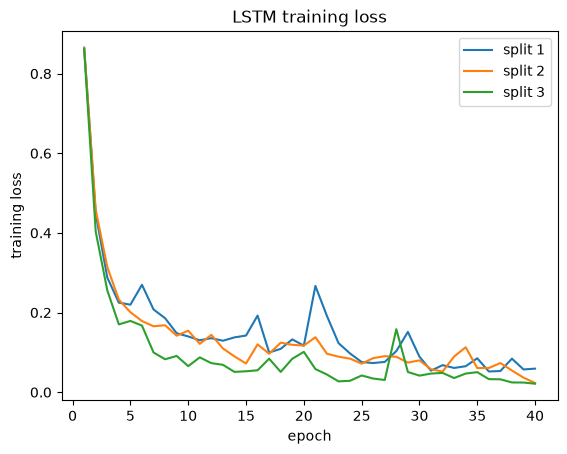

In [6]:
for n, model in enumerate(lstm_models, start=1):
    plt.plot(range(1, len(model.loss_history) + 1), model.loss_history, label=f"split {n}")
plt.xlabel("epoch")
plt.ylabel("training loss")
plt.title("LSTM training loss")
plt.legend()
plt.show()

## 5. Comparison

In [7]:
pd.DataFrame({"Random Forest": forest_scores, "LSTM": lstm_scores},
             index=[f"split {n}" for n in range(1, len(splits) + 1)]).T.assign(
    mean=lambda t: t.mean(axis=1)).style.format("{:.1%}")

,split 1,split 2,split 3,mean
Random Forest,98.4%,98.4%,91.3%,96.1%
LSTM,98.4%,99.1%,92.2%,96.6%


## 6. Errors of the LSTM on split 1

              precision    recall  f1-score   support

        curl      0.939     1.000     0.968       107
      pushup      1.000     1.000     1.000       196
       squat      1.000     0.952     0.975       145

    accuracy                          0.984       448
   macro avg      0.980     0.984     0.981       448
weighted avg      0.985     0.984     0.984       448



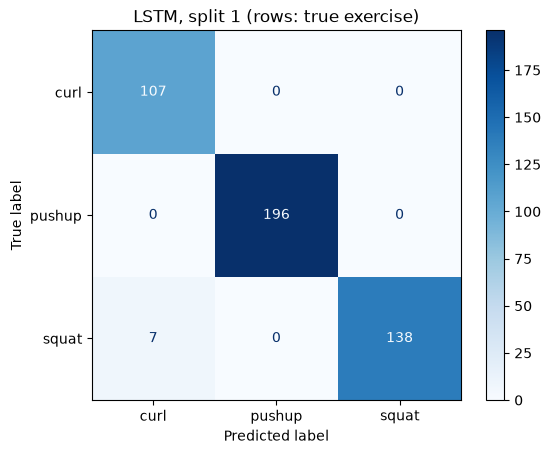

In [8]:
train, test = splits[0]
predicted = predict(lstm_models[0], X[test])
print(classification_report(y[test], predicted, target_names=classes, digits=3))
ConfusionMatrixDisplay.from_predictions(y[test], predicted, display_labels=classes, cmap="Blues")
plt.title("LSTM, split 1 (rows: true exercise)")
plt.show()

## 7. Conclusions

- Both models reach about **96–97% mean accuracy** on unseen videos (roadmap target: > 80%).
  The difference between them is within what chance could explain on this little data.
- The **LSTM is used** in the app: it is as accurate and about 10× faster
  (2.6 ms vs 28 ms per prediction, see `src/benchmark_speed.py`).
- The main confusion is **squat ↔ curl**: both are standing exercises, and a 1-second window
  of someone standing between squats looks like a curl.
- The weakest split is the one with the fewest squat videos for training, so more squat
  data is the clearest way to improve. Voting over all windows of a video
  (`src/predict.py`) removes most single-window errors.